# AI-Driven Crop and Fertiliser Recommendation System — Units 1 and 2

This notebook implements three machine-learning tasks for the project:

| Task | Type | Dataset | Algorithms tried |
|---|---|---|---|
| Recommend the best crop for a field | Classification (supervised) | Kaggle Crop Recommendation, 2,200 rows, labelled | SVM (4 kernels), Decision Tree, KNN, Logistic Regression, Naive Bayes, Neural Network |
| Estimate soil potassium (K) from the other readings | Regression (supervised) | Same crop dataset | Linear Regression, Ridge, Bayesian Ridge, Huber, SVR (4 kernels) |
| Group soil tests into fertiliser zones | Clustering (unsupervised) | Kaggle Soil Fertility (India), 880 soil tests, label removed | K-means, Gaussian Mixture Model, Factor Analysis |

For every algorithm the key hyperparameter is varied, the best value is chosen with **5-fold cross-validation on the training data only**, and the tuned models are then compared on a held-out test set.

Both datasets load from public URLs. Run with **Runtime → Run all**.

In [1]:
import pandas as pd, numpy as np, time, warnings
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, BayesianRidge, HuberRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import FactorAnalysis
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix,
                             r2_score, mean_squared_error, mean_absolute_error,
                             silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score)
sns.set_theme(style='whitegrid', font_scale=1.0)
PAL = ['#2C5F2D', '#97BC62', '#C9A227', '#B5651D', '#5B7FA6', '#8E6C8A']

---
# 1. Load the datasets

In [3]:
crop = pd.read_csv('https://raw.githubusercontent.com/gireesh777/Crop_Recommendation_System_using_ML/master/Dataset/Crop_recommendation.csv')
soil_raw = pd.read_csv('https://raw.githubusercontent.com/AgriWiseGP/ML---Soil-Quality/main/Data/Raw%20Data.csv')
print('Crop dataset:', crop.shape, '| Soil dataset (raw):', soil_raw.shape)
crop.head()

Crop dataset: (2200, 8) | Soil dataset (raw): (1288, 13)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


---
# 2. Preprocessing — crop dataset (labelled)
### 2.1 Data quality checks

In [4]:
feats = ['N','P','K','temperature','humidity','ph','rainfall']
print('Data types:'); print(crop.dtypes.to_string())
print('\nMissing values:', crop.isnull().sum().sum())
print('Duplicate rows:', crop.duplicated().sum())
print('Number of crops:', crop.label.nunique(), '| rows per crop:', crop.label.value_counts().unique())

Data types:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str

Missing values: 0
Duplicate rows: 0
Number of crops: 22 | rows per crop: [100]


No missing values, no duplicates, and exactly 100 rows for each of the 22 crops, so no imputation, de-duplication or class rebalancing is needed.

### 2.2 Outlier check (IQR rule)

In [5]:
q1, q3 = crop[feats].quantile(.25), crop[feats].quantile(.75); iqr = q3 - q1
outliers = ((crop[feats] < q1 - 1.5*iqr) | (crop[feats] > q3 + 1.5*iqr)).sum()
print(outliers.to_string())
print('\nCrops behind the potassium "outliers":', crop.loc[crop.K > q3.K + 1.5*iqr.K, 'label'].unique())

N                0
P              138
K              200
temperature     86
humidity        30
ph              57
rainfall       100

Crops behind the potassium "outliers": <StringArray>
['grapes', 'apple']
Length: 2, dtype: str


Values flagged as outliers are **kept**. They are not errors: they belong to whole crops with genuinely extreme needs (for example apple and grapes need about 200 units of potassium, rice needs up to 300 mm of rain). Removing them would delete entire crops from the data.

### 2.3 Feature scales differ widely → scaling is needed

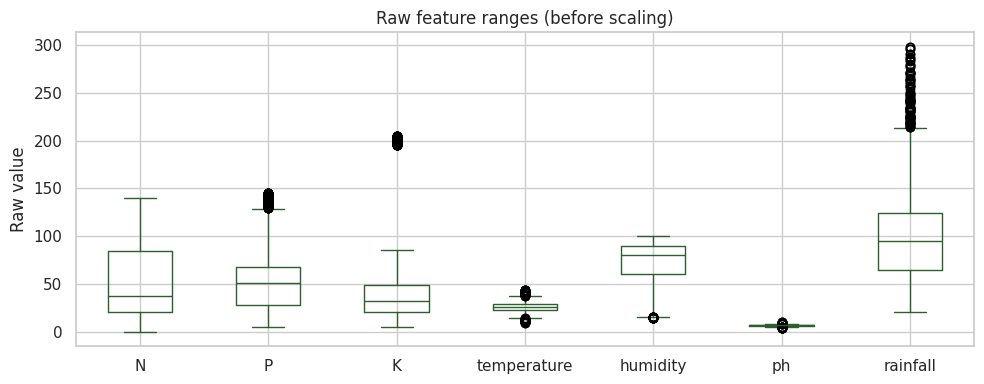

                   min         max
N             0.000000  140.000000
P             5.000000  145.000000
K             5.000000  205.000000
temperature   8.825675   43.675493
humidity     14.258040   99.981876
ph            3.504752    9.935091
rainfall     20.211267  298.560117


In [6]:
fig, ax = plt.subplots(figsize=(10,4))
crop[feats].plot.box(ax=ax, color=PAL[0]); ax.set_title('Raw feature ranges (before scaling)'); ax.set_ylabel('Raw value')
plt.tight_layout(); plt.show()
print(crop[feats].agg(['min','max']).T)

Rainfall reaches ~300 while pH stays between 3.5 and 10. Distance- and margin-based models (**SVM, KNN, Logistic Regression, Neural Network**) would treat rainfall as far more important just because its numbers are bigger. **StandardScaler** rescales every feature to mean 0 and standard deviation 1.

Naive Bayes and Decision Trees don't need scaling (Naive Bayes models each feature separately; trees split on one feature at a time), so they are trained on raw values.

### 2.4 Train/test split and leakage-free scaling

In [7]:
X, y = crop[feats], crop['label']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Training rows:', len(X_tr), '| Test rows:', len(X_te))
print('Rows per crop in test set:', y_te.value_counts().unique())
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Training rows: 1760 | Test rows: 440
Rows per crop in test set: [20]


- **80/20 split, stratified** by crop, so every crop has 80 training rows and 20 test rows.
- The test set is **never used for tuning**. Hyperparameters are chosen with 5-fold cross-validation on the training set only.
- Scaling is placed **inside a Pipeline**, so the scaler learns its mean and standard deviation from training folds only. Fitting it on all the data first would leak test information into training.
- Crop names are used directly as class labels; scikit-learn encodes them internally, so no manual label encoding is needed.

---
# 3. Preprocessing — soil dataset (unlabelled)
### 3.1 Remove duplicated rows

In [8]:
print('Raw rows:', len(soil_raw), '| duplicate rows:', soil_raw.duplicated().sum())
soil = soil_raw.drop_duplicates().reset_index(drop=True)
print('Rows after removing duplicates:', len(soil), '| missing values:', soil.isnull().sum().sum())

Raw rows: 1288 | duplicate rows: 408
Rows after removing duplicates: 880 | missing values: 0


The public copy contains 408 exact copies added by a previous user to rebalance one class. They are removed, leaving the **880 genuine soil tests**.

### 3.2 Remove the label so the data is unlabelled

In [9]:
hidden = soil.pop('fertility')     # removed before modelling; used ONLY at the end to evaluate the clusters
print('Columns used:', list(soil.columns))

Columns used: ['N', 'P', 'K', 'ph', 'ec', 'oc', 'S', 'zn', 'fe', 'cu', 'Mn', 'B']


### 3.3 Handle implausible readings

In [10]:
print(soil.describe().T[['min','max']].round(2))
low, high = soil.quantile(.01), soil.quantile(.99)
print('\nValues clipped to the 1st-99th percentile range:', int(((soil < low) | (soil > high)).sum().sum()))
soil_c = soil.clip(low, high, axis=1)

      min     max
N    6.00  383.00
P    2.90  125.00
K   11.00  887.00
ph   0.90   11.15
ec   0.10    0.95
oc   0.10   24.00
S    0.64   31.00
zn   0.07   42.00
fe   0.21   44.00
cu   0.09    3.02
Mn   0.11   31.00
B    0.06    2.82

Values clipped to the 1st-99th percentile range: 180


Some readings are physically implausible — a soil pH below 1, organic carbon of 24%. Clustering is very sensitive to extreme values (one bad reading can pull a cluster centre), so each feature is **clipped to its 1st–99th percentile range** rather than deleting rows.

### 3.4 Feature selection and scaling

In [11]:
Z = StandardScaler().fit_transform(soil_c[['N','P','K']])            # for K-means and GMM
Z12 = StandardScaler().fit_transform(np.log1p(soil_c))                 # for Factor Analysis (all 12 nutrients)
print('Clustering matrix:', Z.shape, '| Factor-analysis matrix:', Z12.shape)

Clustering matrix: (880, 3) | Factor-analysis matrix: (880, 12)


- **K-means and GMM use N, P and K** — the nutrients that decide fertiliser needs, and the ones India's Soil Health Card rates as Low/Medium/High. They are standardised so no nutrient dominates the distance calculation.
- **Factor Analysis uses all 12 nutrients**. Most micronutrients are strongly right-skewed, so a log transform is applied first, then standardisation, because Factor Analysis assumes roughly bell-shaped features.

---
# 4. Classification — recommending the crop
### 4.1 SVM: accuracy for different kernels
Each kernel is tuned over C (how strictly the margin fits the training data), so every kernel is compared at its own best setting.

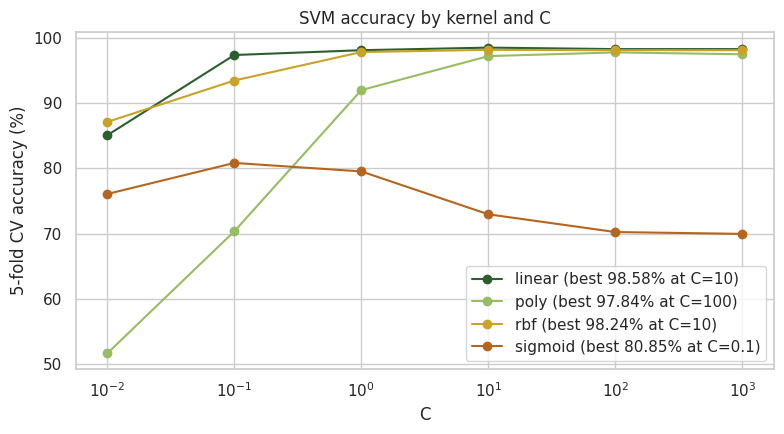

,best C,CV accuracy %,test accuracy %
linear,10.0,98.58,98.86
poly,100.0,97.84,98.86
rbf,10.0,98.24,98.86
sigmoid,0.1,80.85,81.36


In [12]:
Cs = [0.01, 0.1, 1, 10, 100, 1000]; kern = {}
for k in ['linear','poly','rbf','sigmoid']:
    g = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel=k)), {'svc__C': Cs}, cv=cv, n_jobs=-1).fit(X_tr, y_tr)
    kern[k] = dict(scores=g.cv_results_['mean_test_score']*100, best_C=g.best_params_['svc__C'], best=g.best_score_*100,
                   test=accuracy_score(y_te, g.predict(X_te))*100)
plt.figure(figsize=(8,4.5))
for (k,v),c in zip(kern.items(), PAL): plt.plot(Cs, v['scores'], 'o-', color=c, label=f"{k} (best {v['best']:.2f}% at C={v['best_C']})")
plt.xscale('log'); plt.xlabel('C'); plt.ylabel('5-fold CV accuracy (%)'); plt.title('SVM accuracy by kernel and C'); plt.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({k: {'best C': v['best_C'], 'CV accuracy %': round(v['best'],2), 'test accuracy %': round(v['test'],2)} for k,v in kern.items()}).T

**Linear kernel wins (98.58%)**, with RBF and polynomial close behind. After scaling, the 22 crops are already almost separable with straight boundaries, so curved kernels add complexity without gaining accuracy. The **sigmoid kernel fails (~81%)** and gets *worse* as C grows — it is not a valid similarity measure for this data. Small C (0.01) underfits every kernel.

### 4.2 Hyperparameter tuning for every classifier

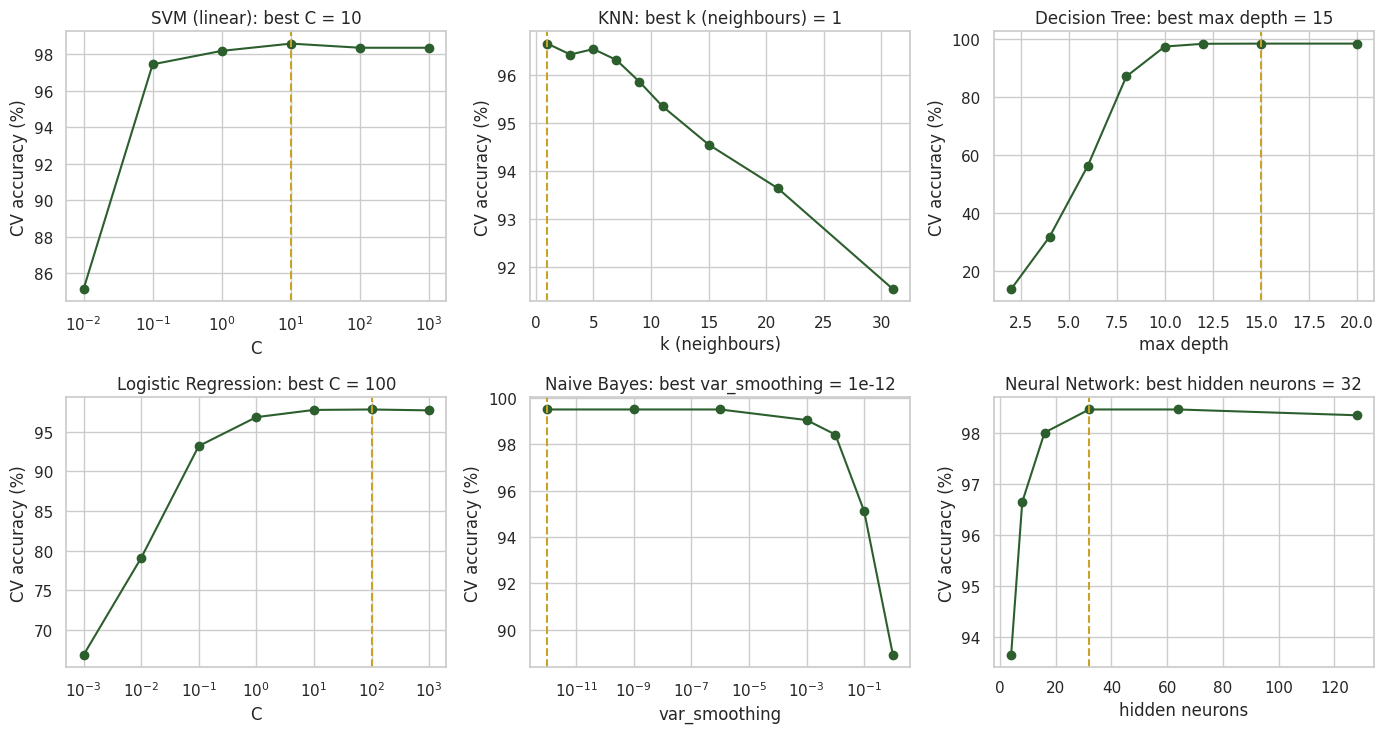

,0.001,0.01,0.1,1,10,100,1000,11,12,128,...,3,31,32,4,5,6,64,7,8,9
SVM (linear),NaN,85.11,97.44,98.18,98.58,98.35,98.35,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
KNN,NaN,NaN,NaN,96.65,NaN,NaN,NaN,95.34,NaN,NaN,...,96.42,91.53,NaN,NaN,96.53,NaN,NaN,96.31,NaN,95.85
Decision Tree,NaN,NaN,NaN,NaN,97.50,NaN,NaN,NaN,98.47,NaN,...,NaN,NaN,NaN,31.70,NaN,56.36,NaN,NaN,87.16,NaN
Logistic Regression,66.88,79.09,93.18,96.82,97.73,97.78,97.67,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Naive Bayes,99.03,98.41,95.11,88.92,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Neural Network,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.35,...,NaN,NaN,98.47,93.64,NaN,NaN,98.47,NaN,96.65,NaN


In [13]:
sweeps = {
 'SVM (linear)':        (make_pipeline(StandardScaler(), SVC(kernel='linear')), 'svc__C', [0.01,0.1,1,10,100,1000], 'C', True),
 'KNN':                 (make_pipeline(StandardScaler(), KNeighborsClassifier()), 'kneighborsclassifier__n_neighbors', [1,3,5,7,9,11,15,21,31], 'k (neighbours)', False),
 'Decision Tree':       (DecisionTreeClassifier(random_state=42), 'max_depth', [2,4,6,8,10,12,15,20], 'max depth', False),
 'Logistic Regression': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), 'logisticregression__C', [0.001,0.01,0.1,1,10,100,1000], 'C', True),
 'Naive Bayes':         (GaussianNB(), 'var_smoothing', [1e-12,1e-9,1e-6,1e-3,1e-2,1e-1,1], 'var_smoothing', True),
 'Neural Network':      (make_pipeline(StandardScaler(), MLPClassifier(max_iter=2000, random_state=42)), 'mlpclassifier__hidden_layer_sizes', [(4,),(8,),(16,),(32,),(64,),(128,)], 'hidden neurons', False),
}
best_clf, sweep_res = {}, {}
fig, axes = plt.subplots(2, 3, figsize=(14,7.5))
for ax, (name, (model, p, vals, label, log)) in zip(axes.ravel(), sweeps.items()):
    g = GridSearchCV(model, {p: vals}, cv=cv, n_jobs=-1).fit(X_tr, y_tr)
    best_clf[name] = g.best_estimator_
    sc = g.cv_results_['mean_test_score']*100
    xs = [v[0] for v in vals] if isinstance(vals[0], tuple) else vals
    sweep_res[name] = pd.Series(sc.round(2), index=[str(v) for v in xs])
    ax.plot(xs, sc, 'o-', color=PAL[0]); ax.set_title(f"{name}: best {label} = {xs[int(np.argmax(sc))]}")
    ax.set_xlabel(label); ax.set_ylabel('CV accuracy (%)')
    if log: ax.set_xscale('log')
    ax.axvline(xs[int(np.argmax(sc))], color=PAL[2], ls='--')
plt.tight_layout(); plt.show()
pd.DataFrame(sweep_res).T

**How each best value was chosen:** the value with the highest mean 5-fold CV accuracy on the training set.

- **SVM C = 10:** C = 0.01 underfits (85%); beyond 10 accuracy is flat.
- **KNN k = 1:** accuracy falls steadily as k grows, because large k mixes in neighbours from other crops. k = 1–5 are almost tied, so KNN is sensitive to individual noisy points.
- **Decision Tree max depth = 15:** shallow trees can't separate 22 crops (13.6% at depth 2); accuracy plateaus from depth 12.
- **Logistic Regression C = 100:** strong regularisation (small C) underfits badly (66.9% at C = 0.001).
- **Naive Bayes var_smoothing ≤ 1e-6:** small smoothing leaves the learned bell curves intact; large smoothing blurs them and accuracy drops to 88.9%.
- **Neural Network 64 hidden neurons:** too few neurons (4) can't learn 22 classes; beyond 32–64 there is no further gain.

### 4.3 Comparing the tuned classifiers on the test set

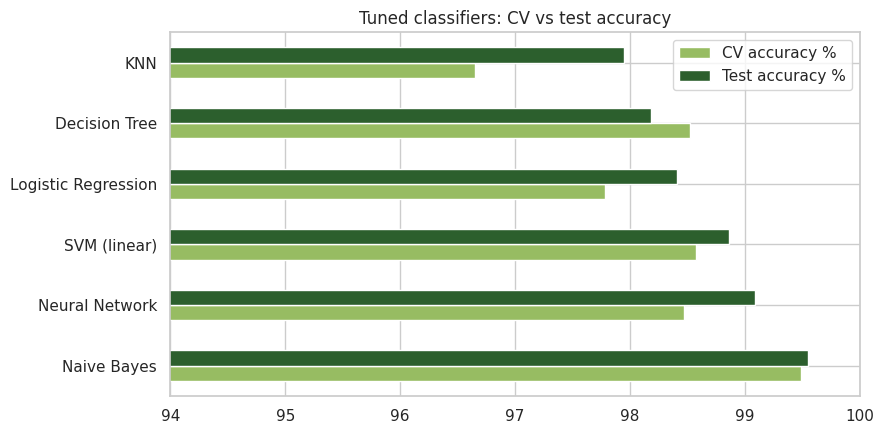

,CV accuracy %,CV std %,Test accuracy %,Precision %,Recall %,F1 %,Wrong (of 440),Train time (ms)
Naive Bayes,99.49,0.42,99.55,99.59,99.55,99.54,2.0,4.0
Neural Network,98.47,0.53,99.09,99.15,99.09,99.09,4.0,1738.0
SVM (linear),98.58,0.18,98.86,98.97,98.86,98.86,5.0,21.3
Logistic Regression,97.78,0.58,98.41,98.52,98.41,98.40,7.0,57.9
Decision Tree,98.52,0.71,98.18,98.30,98.18,98.17,8.0,13.2
KNN,96.65,0.45,97.95,98.02,97.95,97.94,9.0,4.7


In [14]:
rows = {}
for name, m in best_clf.items():
    cvs = cross_val_score(m, X_tr, y_tr, cv=cv)
    t = time.time(); m.fit(X_tr, y_tr); fit_ms = (time.time()-t)*1000
    p = m.predict(X_te)
    rows[name] = {'CV accuracy %': round(cvs.mean()*100,2), 'CV std %': round(cvs.std()*100,2),
                  'Test accuracy %': round(accuracy_score(y_te,p)*100,2), 'Precision %': round(precision_score(y_te,p,average='macro')*100,2),
                  'Recall %': round(recall_score(y_te,p,average='macro')*100,2), 'F1 %': round(f1_score(y_te,p,average='macro')*100,2),
                  'Wrong (of 440)': int((p != y_te).sum()), 'Train time (ms)': round(fit_ms,1)}
clf_table = pd.DataFrame(rows).T.sort_values('Test accuracy %', ascending=False)
ax = clf_table[['CV accuracy %','Test accuracy %']].plot.barh(figsize=(9,4.5), color=[PAL[1], PAL[0]])
ax.set_xlim(94, 100); ax.set_title('Tuned classifiers: CV vs test accuracy'); plt.tight_layout(); plt.show()
clf_table

**Gaussian Naive Bayes is chosen.** It has the highest CV accuracy (99.49%) and test accuracy (99.55%, only 2 of 440 wrong — both are rice fields predicted as jute, two crops that need very similar wet, humid conditions), has no settings that need careful tuning, and trains in a few milliseconds. Its assumption — each feature follows a bell curve within each crop — fits this data well. It also gives a probability for every crop, which supports the project's explainability goal.

Why the others were not chosen:
- **Neural Network:** second-best on the test set (4 wrong) but trains hundreds of times slower, and its predictions are harder to explain.
- **SVM (linear):** the most consistent across CV folds (std 0.18%) and strong on test (5 wrong), but still below Naive Bayes, and it needs scaling and C tuning.
- **Logistic Regression:** 7 wrong; needs a very large C (weak regularisation) to fit 22 classes.
- **Decision Tree:** 8 wrong; needs a deep tree (depth 15), which is prone to overfitting.
- **KNN:** lowest (9 wrong); the best k is 1, meaning it memorises single training points.

### 4.4 Performance metrics of the chosen model (Gaussian Naive Bayes)

              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      1.000     1.000     1.000        20
   blackgram      1.000     1.000     1.000        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
      grapes      1.000     1.000     1.000        20
        jute      0.909     1.000     0.952        20
 kidneybeans      1.000     1.000     1.000        20
      lentil      1.000     1.000     1.000        20
       maize      1.000     1.000     1.000        20
       mango      1.000     1.000     1.000        20
   mothbeans      1.000     1.000     1.000        20
    mungbean      1.000     1.000     1.000        20
   muskmelon      1.000     1.000     1.000        20
      orange      1.000     1.000     1.000        20
      papaya      1.000    

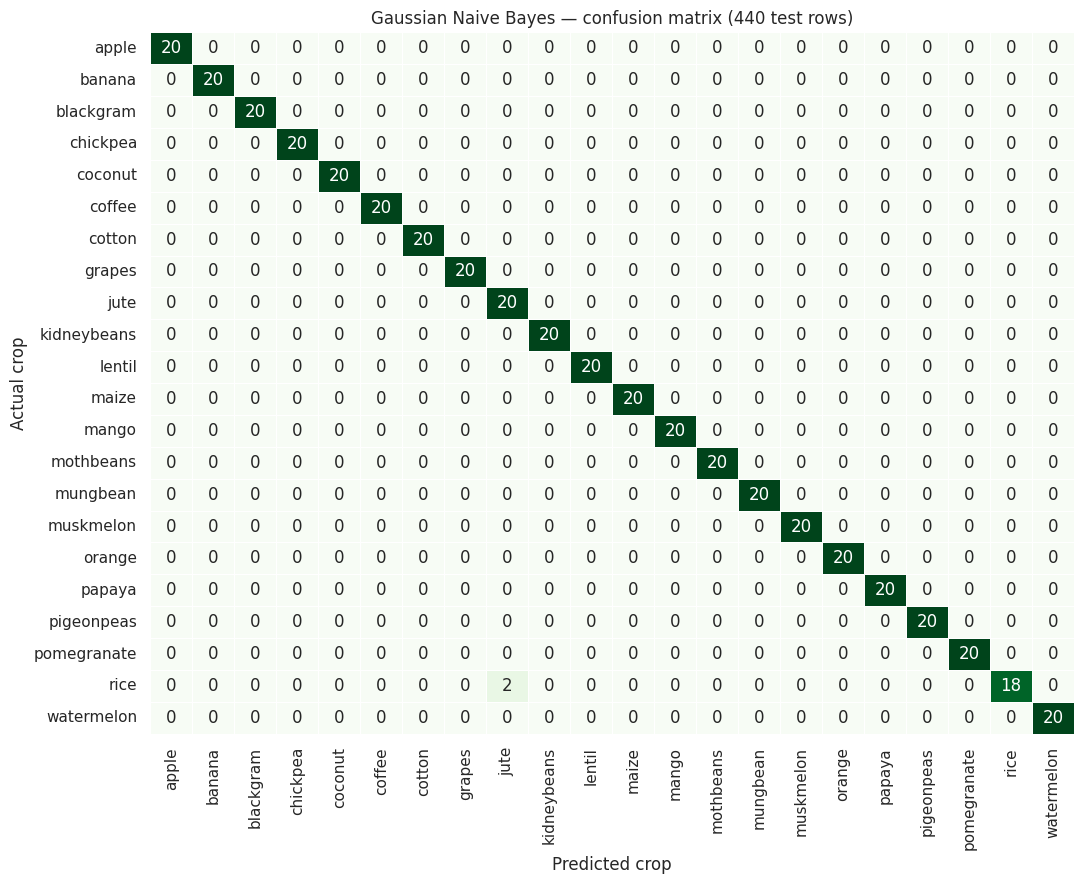

In [15]:
gnb = best_clf['Naive Bayes']; pred = gnb.predict(X_te)
print(classification_report(y_te, pred, digits=3))
plt.figure(figsize=(11,9))
sns.heatmap(confusion_matrix(y_te, pred, labels=gnb.classes_), xticklabels=gnb.classes_, yticklabels=gnb.classes_,
            annot=True, fmt='d', cmap='Greens', cbar=False, linewidths=.5)
plt.xlabel('Predicted crop'); plt.ylabel('Actual crop'); plt.title('Gaussian Naive Bayes — confusion matrix (440 test rows)')
plt.tight_layout(); plt.show()

---
# 5. Regression — estimating soil potassium (K)
Potassium is predicted from the other six readings (N, P, temperature, humidity, pH, rainfall). The same stratified 80/20 split is used, and the **crop label is not used as an input**.

In [16]:
Xr = crop[['N','P','temperature','humidity','ph','rainfall']]; yr = crop['K']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, stratify=crop.label, random_state=42)
kcv = KFold(n_splits=5, shuffle=True, random_state=42)
print('Train:', len(Xr_tr), '| Test:', len(Xr_te), '| K ranges', yr.min(), '-', yr.max())

Train: 1760 | Test: 440 | K ranges 5 - 205


### 5.1 SVR: R² for different kernels (each tuned over C)

In [17]:
rC = [1, 10, 100, 1000]; rkern = {}
for k in ['linear','poly','rbf','sigmoid']:
    g = GridSearchCV(make_pipeline(StandardScaler(), SVR(kernel=k)), {'svr__C': rC}, cv=kcv, scoring='r2', n_jobs=-1).fit(Xr_tr, yr_tr)
    rkern[k] = {'best C': g.best_params_['svr__C'], 'CV R²': round(g.best_score_,3), 'test R²': round(r2_score(yr_te, g.predict(Xr_te)),3),
                'R² per C': np.round(g.cv_results_['mean_test_score'],3).tolist()}
pd.DataFrame(rkern).T

,best C,CV R²,test R²,R² per C
linear,1000,0.299,0.314,"[0.274, 0.296, 0.298, 0.299]"
poly,100,0.892,0.908,"[0.865, 0.891, 0.892, 0.892]"
rbf,1000,0.983,0.984,"[0.597, 0.966, 0.98, 0.983]"
sigmoid,1,-0.409,-0.565,"[-0.409, -14.212, -1068.003, -102478.81]"


**RBF kernel wins (R² ≈ 0.98)**, polynomial is second (≈ 0.89), linear is poor (≈ 0.30). The relationship between potassium and the other readings is **curved, not a straight line**, so a curved kernel captures it. The **sigmoid kernel fails completely** (R² below 0, worse than always predicting the average) and collapses further as C grows.

### 5.2 Hyperparameter tuning for the regressors

Ridge {0.001: np.float64(0.628), 0.01: np.float64(0.628), 0.1: np.float64(0.628), 1: np.float64(0.628), 10: np.float64(0.628), 100: np.float64(0.625), 1000: np.float64(0.515)}
Huber {1.1: np.float64(0.324), 1.35: np.float64(0.54), 1.5: np.float64(0.623), 2.0: np.float64(0.627), 3.0: np.float64(0.628)}


SVR (RBF) {1: np.float64(0.597), 10: np.float64(0.966), 100: np.float64(0.98), 1000: np.float64(0.983), 5000: np.float64(0.982)}


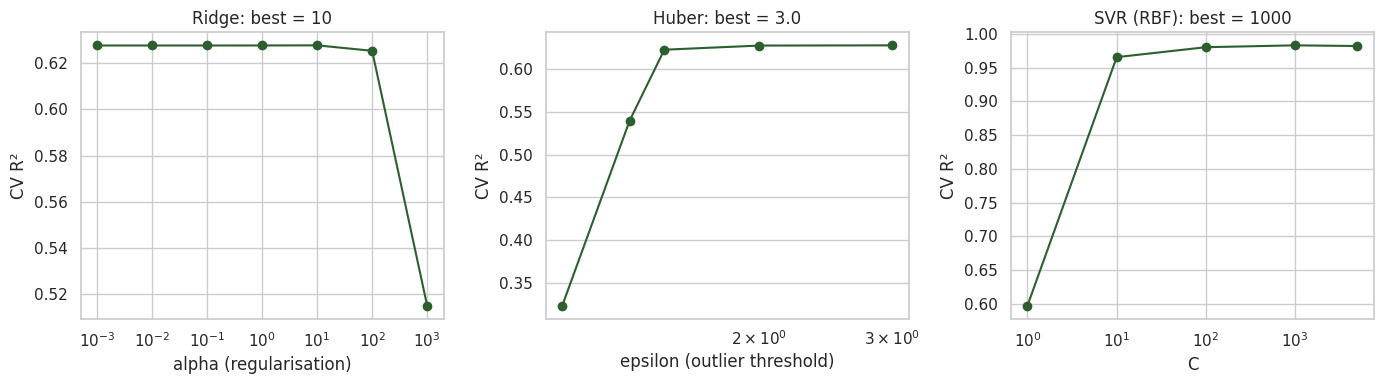

Bayesian Ridge learned its own regularisation: alpha (noise precision) = 0.00108, lambda (weight precision) = 0.00347


In [18]:
rsweeps = {
 'Ridge':     (make_pipeline(StandardScaler(), Ridge()), 'ridge__alpha', [0.001,0.01,0.1,1,10,100,1000], 'alpha (regularisation)'),
 'Huber':     (make_pipeline(StandardScaler(), HuberRegressor(max_iter=2000)), 'huberregressor__epsilon', [1.1,1.35,1.5,2.0,3.0], 'epsilon (outlier threshold)'),
 'SVR (RBF)': (make_pipeline(StandardScaler(), SVR(kernel='rbf')), 'svr__C', [1,10,100,1000,5000], 'C'),
}
best_reg = {'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
            'Bayesian Ridge': make_pipeline(StandardScaler(), BayesianRidge())}
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, (name, (m, p, vals, label)) in zip(axes, rsweeps.items()):
    g = GridSearchCV(m, {p: vals}, cv=kcv, scoring='r2', n_jobs=-1).fit(Xr_tr, yr_tr)
    best_reg[name] = g.best_estimator_; sc = g.cv_results_['mean_test_score']
    ax.plot(vals, sc, 'o-', color=PAL[0]); ax.set_xscale('log'); ax.set_xlabel(label); ax.set_ylabel('CV R²')
    ax.set_title(f"{name}: best = {g.best_params_[p]}"); print(name, dict(zip(vals, sc.round(3))))
plt.tight_layout(); plt.show()
br = best_reg['Bayesian Ridge'].fit(Xr_tr, yr_tr)[-1]
print(f"Bayesian Ridge learned its own regularisation: alpha (noise precision) = {br.alpha_:.5f}, lambda (weight precision) = {br.lambda_:.5f}")

- **Ridge alpha:** R² is flat (0.628) from 0.001 to 10 and only drops at 1000. With 6 features and 1,760 training rows the model isn't overfitting, so regularisation has nothing to fix.
- **Huber epsilon:** small epsilon treats many points as outliers and R² falls to 0.32. The high-potassium crops (apple, grapes) are real, not errors, so the best epsilon (3.0) makes Huber behave like ordinary least squares.
- **Bayesian Ridge** has no value to tune: it learns its regularisation from the data. The learned weight precision is tiny (≈0.003), i.e. almost no regularisation — confirming the Ridge result.
- **SVR C:** small C underfits (0.60 at C = 1); accuracy peaks at C = 1000.

### 5.3 Comparing the tuned regressors on the test set

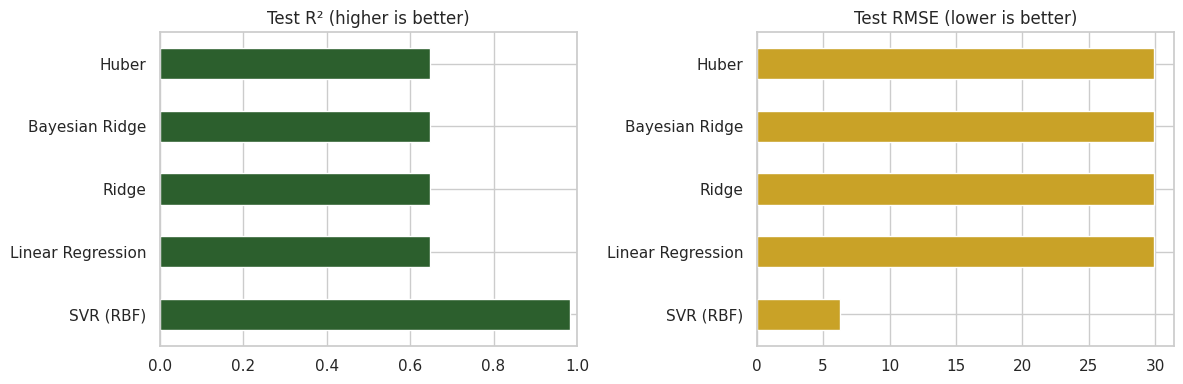

,CV R²,Test R²,RMSE,MAE
SVR (RBF),0.983,0.984,6.29,4.47
Linear Regression,0.628,0.648,29.92,25.71
Ridge,0.628,0.648,29.92,25.70
Bayesian Ridge,0.628,0.648,29.92,25.70
Huber,0.628,0.648,29.92,25.71


In [19]:
rrows = {}
for name in ['Linear Regression','Ridge','Bayesian Ridge','Huber','SVR (RBF)']:
    m = best_reg[name]; cvs = cross_val_score(m, Xr_tr, yr_tr, cv=kcv, scoring='r2')
    p = m.fit(Xr_tr, yr_tr).predict(Xr_te)
    rrows[name] = {'CV R²': round(cvs.mean(),3), 'Test R²': round(r2_score(yr_te,p),3),
                   'RMSE': round(mean_squared_error(yr_te,p)**0.5,2), 'MAE': round(mean_absolute_error(yr_te,p),2)}
reg_table = pd.DataFrame(rrows).T.sort_values('Test R²', ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12,4))
reg_table['Test R²'].plot.barh(ax=ax[0], color=PAL[0]); ax[0].set_title('Test R² (higher is better)'); ax[0].set_xlim(0,1)
reg_table['RMSE'].plot.barh(ax=ax[1], color=PAL[2]); ax[1].set_title('Test RMSE (lower is better)')
plt.tight_layout(); plt.show()
reg_table

**SVR with RBF kernel is chosen**: test R² = 0.984, typical error (MAE) ≈ 4.5 units of K.

All four straight-line models land on the same score (R² 0.648, error ≈ 26 units). They differ only in how they handle overfitting (Ridge, Bayesian Ridge) or outliers (Huber) — but this data has neither problem. Its problem is that the relationship is curved, which only the kernel model can capture.

### 5.4 Performance of the chosen model — predicted vs actual

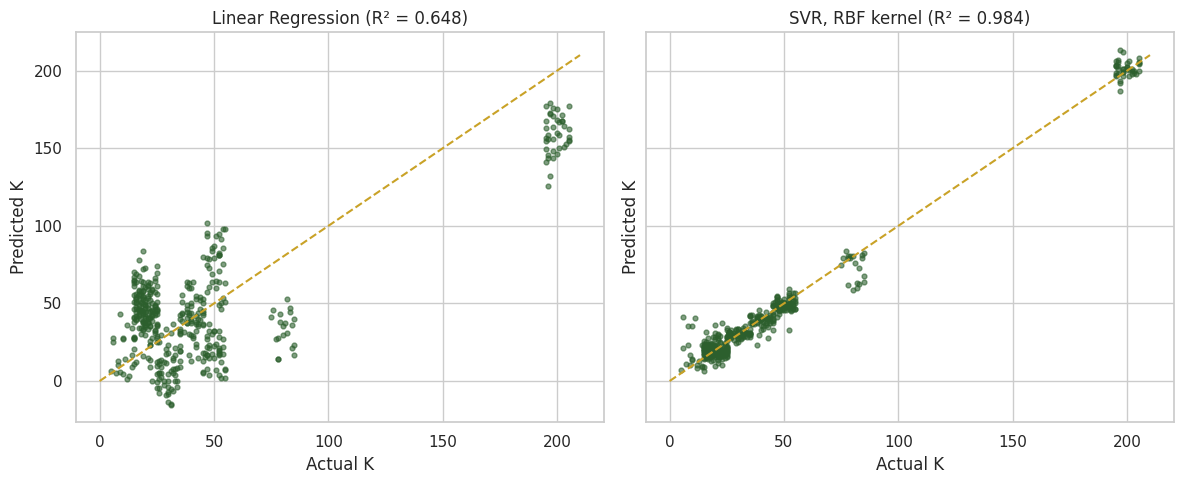

In [20]:
p_svr = best_reg['SVR (RBF)'].predict(Xr_te); p_lin = best_reg['Linear Regression'].predict(Xr_te)
fig, ax = plt.subplots(1, 2, figsize=(12,5), sharey=True)
for a, p, t in [(ax[0], p_lin, f'Linear Regression (R² = {r2_score(yr_te,p_lin):.3f})'), (ax[1], p_svr, f'SVR, RBF kernel (R² = {r2_score(yr_te,p_svr):.3f})')]:
    a.scatter(yr_te, p, s=12, alpha=.6, color=PAL[0]); a.plot([0,210],[0,210], '--', color=PAL[2]); a.set_title(t)
    a.set_xlabel('Actual K'); a.set_ylabel('Predicted K')
plt.tight_layout(); plt.show()

Points on the dashed line are perfect predictions. SVR's points sit on the line; linear regression's spread widely, especially for the high-potassium crops.

---
# 6. Clustering — fertiliser zones from unlabelled soil tests
### 6.1 K-means: choosing the number of clusters (k)

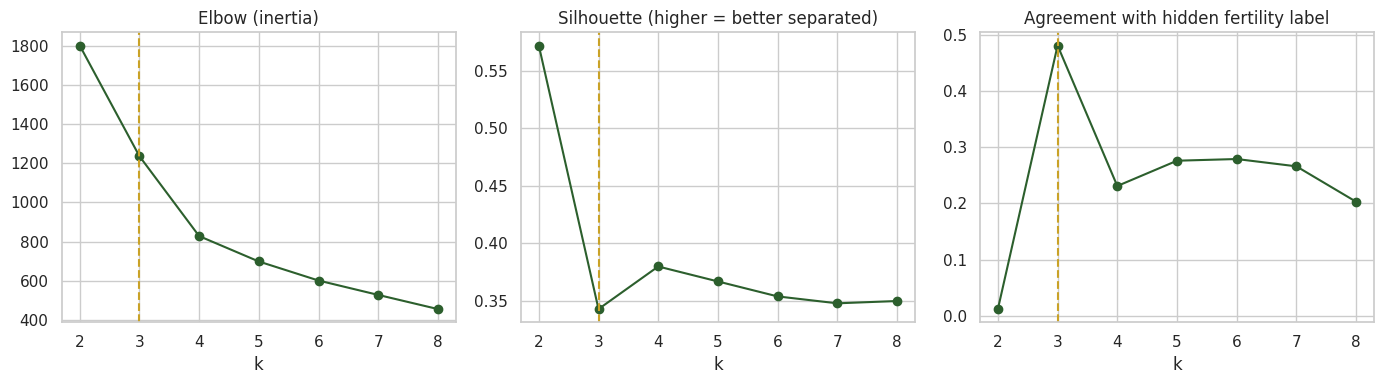

,inertia,silhouette,ARI vs hidden label,cluster sizes
2,1801.5,0.572,0.012,"[67, 813]"
3,1236.0,0.343,0.481,"[478, 335, 67]"
4,827.8,0.38,0.231,"[254, 243, 67, 316]"
5,698.0,0.367,0.276,"[135, 67, 289, 210, 179]"
6,600.7,0.354,0.279,"[120, 251, 67, 170, 81, 191]"
7,527.2,0.348,0.266,"[161, 86, 222, 23, 236, 43, 109]"
8,454.9,0.35,0.203,"[84, 206, 23, 153, 44, 173, 107, 90]"


In [21]:
ks = range(2, 9); km_res = {}
for k in ks:
    lab = KMeans(k, n_init=20, random_state=0).fit_predict(Z)
    km_res[k] = {'inertia': round(KMeans(k, n_init=20, random_state=0).fit(Z).inertia_,1), 'silhouette': round(silhouette_score(Z, lab),3),
                 'ARI vs hidden label': round(adjusted_rand_score(hidden, lab),3), 'cluster sizes': np.bincount(lab).tolist()}
km_df = pd.DataFrame(km_res).T
fig, ax = plt.subplots(1, 3, figsize=(14,4))
ax[0].plot(ks, km_df.inertia, 'o-', color=PAL[0]); ax[0].set_title('Elbow (inertia)')
ax[1].plot(ks, km_df.silhouette, 'o-', color=PAL[0]); ax[1].set_title('Silhouette (higher = better separated)')
ax[2].plot(ks, km_df['ARI vs hidden label'], 'o-', color=PAL[0]); ax[2].set_title('Agreement with hidden fertility label')
for a in ax: a.set_xlabel('k'); a.axvline(3, color=PAL[2], ls='--')
plt.tight_layout(); plt.show()
km_df

**k = 3 is chosen.** Silhouette is highest at k = 2, but that split is trivial: it only separates 67 high-phosphorus soils from the other 813 (agreement with the hidden fertility label ≈ 0.01). k = 3 is the smallest k that also separates nitrogen-deficient soils, and it agrees with the hidden fertility label far better than any other k (ARI 0.48 vs ≤ 0.28). Three zones also match the Soil Health Card's Low/Medium/High scale.

### 6.2 Gaussian Mixture Model: number of components and covariance type (BIC)

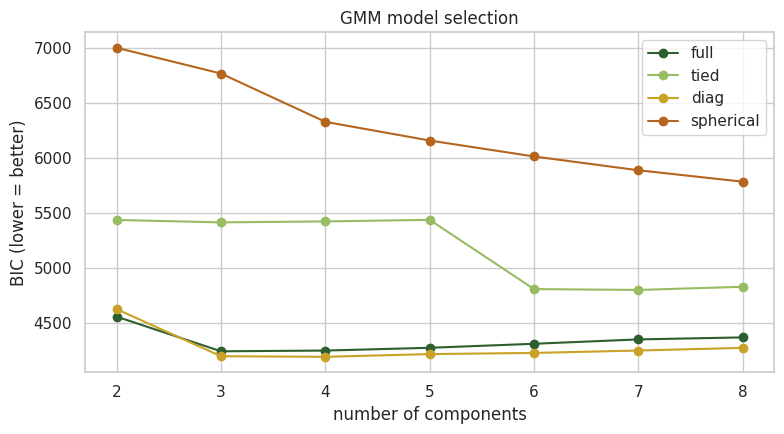

,full,tied,diag,spherical
2,4562.1,5439.8,4629.9,7003.3
3,4247.5,5418.2,4202.8,6769.5
4,4254.2,5426.8,4197.6,6330.9
5,4279.3,5440.9,4222.2,6161.2
6,4315.8,4812.3,4232.6,6016.5
7,4355.4,4804.6,4254.6,5891.2
8,4373.8,4833.3,4278.8,5787.7


In [22]:
gmm_bic = {ct: [GaussianMixture(k, covariance_type=ct, n_init=5, random_state=0).fit(Z).bic(Z) for k in ks] for ct in ['full','tied','diag','spherical']}
plt.figure(figsize=(8,4.5))
for (ct, b), c in zip(gmm_bic.items(), PAL): plt.plot(list(ks), b, 'o-', color=c, label=ct)
plt.xlabel('number of components'); plt.ylabel('BIC (lower = better)'); plt.title('GMM model selection'); plt.legend(); plt.tight_layout(); plt.show()
pd.DataFrame(gmm_bic, index=list(ks)).round(1)

BIC (lower is better) prefers the **diagonal** covariance type, which is best at 3–4 components. Spherical clusters fit worst. For a fair comparison with K-means, GMM is evaluated at 3 components.

### 6.3 Factor Analysis: number of latent factors

{1: np.float64(-17.427), 2: np.float64(-17.168), 3: np.float64(-17.216), 4: np.float64(-17.194), 5: np.float64(-17.189), 6: np.float64(-17.206)} -> best number of factors: 2


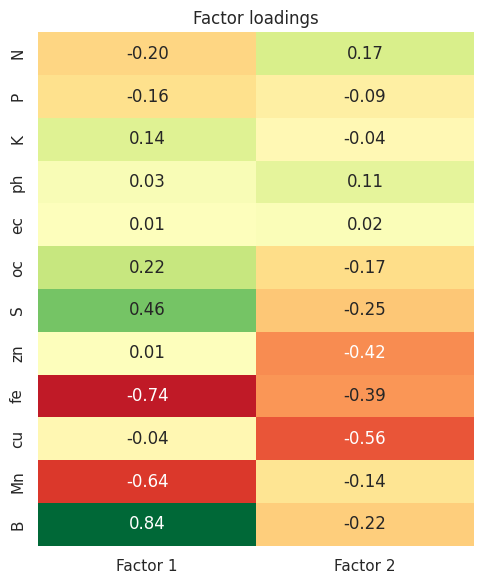

In [23]:
fa_ll = {nf: cross_val_score(FactorAnalysis(nf, random_state=0), Z12, cv=5).mean() for nf in range(1,7)}
nf_best = max(fa_ll, key=fa_ll.get)
print({k: round(v,3) for k,v in fa_ll.items()}, '-> best number of factors:', nf_best)
fa = FactorAnalysis(nf_best, rotation='varimax', random_state=0).fit(Z12)
load = pd.DataFrame(fa.components_.T, index=soil_c.columns, columns=[f'Factor {i+1}' for i in range(nf_best)])
plt.figure(figsize=(5,6)); sns.heatmap(load, annot=True, fmt='.2f', cmap='RdYlGn', center=0, cbar=False)
plt.title('Factor loadings'); plt.tight_layout(); plt.show()
F = fa.transform(Z12)

Cross-validated log-likelihood is highest with **2 factors**. The loadings show both factors are driven by **micronutrients** — Factor 1 by boron and sulphur against iron and manganese, Factor 2 by copper, zinc and iron. N, P and K load weakly on both.

### 6.4 Comparing the clustering approaches (3 clusters each)

In [24]:
def evaluate(lab, space):
    return {'Silhouette': round(silhouette_score(space,lab),3), 'Davies-Bouldin': round(davies_bouldin_score(space,lab),3),
            'Calinski-Harabasz': round(calinski_harabasz_score(space,lab),1), 'ARI vs hidden label': round(adjusted_rand_score(hidden,lab),3)}
km = KMeans(3, n_init=20, random_state=0).fit(Z)
clu_table = pd.DataFrame({
    'K-means on N, P, K': evaluate(km.labels_, Z),
    'GMM (diag) on N, P, K': evaluate(GaussianMixture(3, covariance_type='diag', n_init=5, random_state=0).fit(Z).predict(Z), Z),
    'GMM (full) on N, P, K': evaluate(GaussianMixture(3, covariance_type='full', n_init=5, random_state=0).fit(Z).predict(Z), Z),
    'Factor Analysis (2 factors) + K-means': evaluate(KMeans(3, n_init=20, random_state=0).fit_predict(F), F)}).T
clu_table

,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI vs hidden label
"K-means on N, P, K",0.343,1.023,498.1,0.481
"GMM (diag) on N, P, K",0.131,1.658,284.9,0.180
"GMM (full) on N, P, K",0.134,1.661,286.2,0.178
Factor Analysis (2 factors) + K-means,0.486,0.734,1078.8,0.004


**K-means on N, P, K is chosen.**
- It beats both GMM versions on every measure: GMM's clusters overlap (silhouette 0.13) and barely match the fertility label (ARI 0.18).
- Factor Analysis + K-means has better silhouette, but those scores are measured in a different space, so they can't be compared directly. Its clusters group soils by **micronutrients** and have **no relation** to fertility (ARI 0.004) — not useful for fertiliser advice.
- K-means centres also let a new farm's soil test be assigned to a zone instantly.

### 6.5 Final zones, read with Soil Health Card thresholds

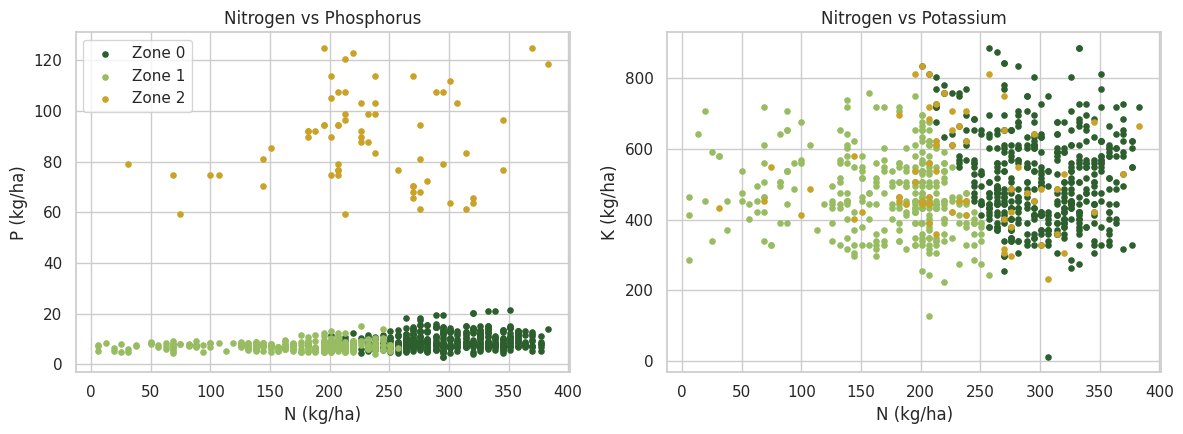

,N,P,K,N level,P level,K level,samples
zone,,,,,,,
0,300.5,9.3,516.8,Medium,Low,High,478
1,173.2,7.3,470.9,Low,Low,High,335
2,231.2,88.6,525.6,Low,High,High,67


In [25]:
soil['zone'] = km.labels_
fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
for z, c in zip(range(3), PAL):
    s = soil[soil.zone == z]; ax[0].scatter(s.N, s.P, s=14, color=c, label=f'Zone {z}'); ax[1].scatter(s.N, s.K, s=14, color=c, label=f'Zone {z}')
ax[0].set(xlabel='N (kg/ha)', ylabel='P (kg/ha)', title='Nitrogen vs Phosphorus'); ax[1].set(xlabel='N (kg/ha)', ylabel='K (kg/ha)', title='Nitrogen vs Potassium')
ax[0].legend(); plt.tight_layout(); plt.show()
prof = soil.groupby('zone')[['N','P','K']].mean().round(1)
lvl = lambda v, lo, hi: 'Low' if v < lo else ('Medium' if v <= hi else 'High')
prof['N level'] = prof.N.apply(lambda v: lvl(v,280,560)); prof['P level'] = prof.P.apply(lambda v: lvl(v,10,25)); prof['K level'] = prof.K.apply(lambda v: lvl(v,108,280))
prof['samples'] = soil.zone.value_counts().sort_index(); prof

| Zone | Soils | Reading | Fertiliser advice |
|---|---|---|---|
| 0 | 478 | Medium N, Low P | Add phosphorus, maintenance nitrogen |
| 1 | 335 | Low N, Low P | Most deficient — add nitrogen and phosphorus |
| 2 | 67 | Low N, very High P | Nitrogen only — avoid more phosphorus |

Potassium is High in every zone, so no potassium fertiliser is needed.

---
# 7. Summary of chosen models

| Task | Chosen model | Key hyperparameter | Result |
|---|---|---|---|
| Crop recommendation | Gaussian Naive Bayes | var_smoothing = 1e-12 | 99.55% test accuracy (2 of 440 wrong) |
| Potassium estimation | SVR, RBF kernel | C = 1000 | Test R² = 0.984, MAE ≈ 4.5 |
| Fertiliser zones | K-means | k = 3, on N, P, K | 3 zones mapped to Soil Health Card levels (ARI 0.48 with hidden label) |